IRRELEVANT VARIABLES


In [1]:
set.seed(3) # you can change the seed or remove the line to see more runs
d<-data.frame(matrix(rnorm(200*100,0,1),nrow=200))
d$out<-rnorm(200,0,1)

In [2]:
lm.all<-lm(out ~ .,data=d)
lm.all.par<-coefficients(summary(lm.all))
sum(lm.all.par[,"Pr(>|t|)"]<0.05)

[1] 4

In [3]:
summary(lm.all) # print out the number of significant independent variables



Call:
lm(formula = out ~ ., data = d)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.71750 -0.55166 -0.04587  0.59639  2.31520 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)  
(Intercept) -1.351e-02  1.113e-01  -0.121   0.9036  
X1          -1.787e-01  1.082e-01  -1.652   0.1018  
X2           2.623e-01  1.124e-01   2.334   0.0216 *
X3           2.221e-01  1.048e-01   2.119   0.0366 *
X4          -1.251e-01  1.211e-01  -1.033   0.3041  
X5          -1.493e-01  1.080e-01  -1.382   0.1700  
X6          -1.037e-01  1.137e-01  -0.911   0.3643  
X7           1.914e-01  1.195e-01   1.601   0.1125  
X8           1.617e-01  1.205e-01   1.342   0.1827  
X9          -6.043e-02  1.084e-01  -0.558   0.5783  
X10          3.401e-02  1.060e-01   0.321   0.7489  
X11         -1.676e-01  1.172e-01  -1.429   0.1561  
X12          9.697e-02  1.115e-01   0.870   0.3866  
X13          3.607e-02  1.063e-01   0.339   0.7351  
X14          3.719e-02  1.090e-01   0.341   0.7

In [4]:
pred<-rownames(lm.all.par)[which(lm.all.par[,"Pr(>|t|)"]==min(lm.all.par[,"Pr(>|t|)"]))] # find the most significant predictor
cor.test(d[[pred]],d$out)


	Pearson's product-moment correlation

data:  d[[pred]] and d$out
t = 2.1997, df = 198, p-value = 0.02899
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.01605274 0.28703994
sample estimates:
      cor 
0.1544498 


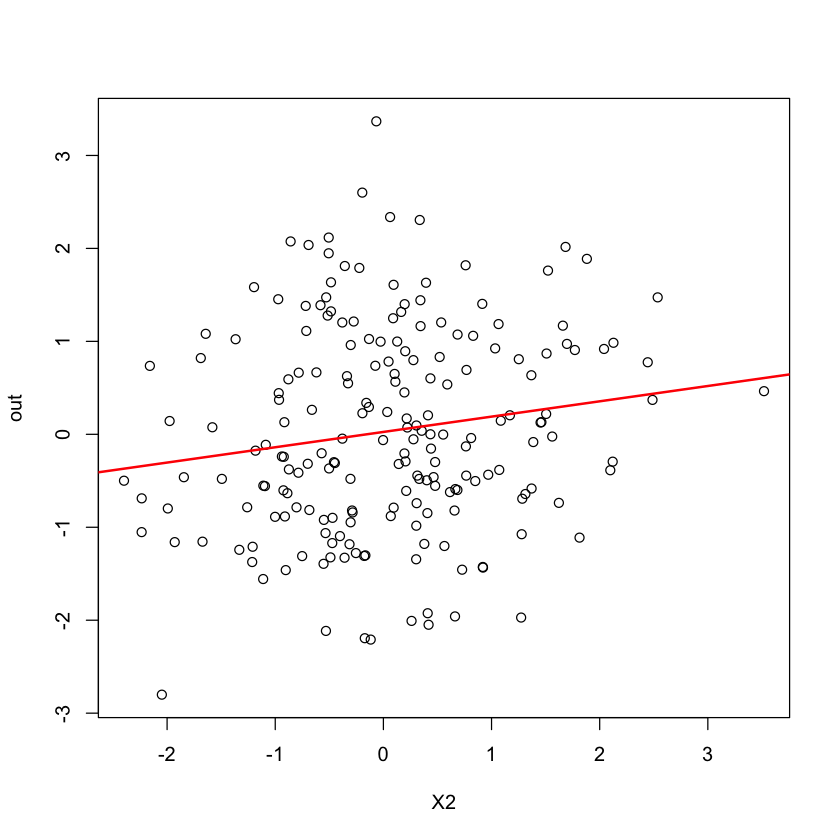

In [7]:
set_plot_defaults()
plot(d[[pred]], d$out,xlab=pred,ylab="out") # visualize the relationship between indep and dep variable
abline(lm(as.formula(paste("out~",pred)), d),col="red", lw=2) # visualize the fit

ALTERNATIVE REGRESSION MODELS

In [8]:
sel.form<-as.formula(paste("out~",paste(rownames(lm.all.par)[lm.all.par[,"Pr(>|t|)"]<0.05],collapse="+")))
lm.sel<- lm(sel.form, data=d) # obviously, it is better to employ lasso or stepwise regression, this is just to illustrate
lm.simple<-lm(out ~ 1,data=d)
lm.zero<-lm(out ~ 0,data=d)

In [11]:
d_test<-data.frame(matrix(rnorm(1000*100,0,1),nrow=1000))
d_test$out<-rnorm(1000,0,1)

myRMSE <- function(predicted, actual) {
  sqrt(mean((predicted - actual)^2))
}

myRMSE(predict(lm.all,d_test),d_test$out)
myRMSE(predict(lm.sel,d_test),d_test$out)
myRMSE(predict(lm.simple,d_test),d_test$out)
myRMSE(predict(lm.zero,d_test),d_test$out)

[1] 1.491519

[1] 1.037562

[1] 0.9926812

[1] 0.9903958

In [12]:
anova(lm.zero,lm.simple,lm.sel,lm.all) 


,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,200,241.7399,NA,NA,NA,NA
2,199,241.5229,1,0.2170007,0.1659505,0.6846156
3,195,224.5144,4,17.0085789,3.2518133,0.0149781
4,99,129.4546,96,95.0597110,0.7572562,0.9138584


In [13]:
anova(lm.zero,lm.all)


,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,200,241.7399,NA,NA,NA,NA
2,99,129.4546,101,112.2853,0.850196,0.7909779


In [20]:
library(cvTools)

Loading required package: lattice



Loading required package: robustbase



In [ ]:
folds <- cvFolds(nrow(d), K = 10, R = 10) # 10 times repeated 10-fold CV
cvFitLmAll <- cvLm(lm.all, cost = rtmspe, folds = folds, trim = 0.1)
cvFitLmSel <- cvLm(lm.sel, cost = rtmspe, folds = folds, trim = 0.1)
cvFitSimple <- cvLm(lm.simple, cost = rtmspe, folds = folds, trim = 0.1)
cvFitZero <- cvLm(lm.zero, cost = rtmspe, folds = folds, trim = 0.1)
cvFits <- cvSelect(ALL = cvFitLmAll, SEL = cvFitLmSel, SIMPLE = cvFitSimple, ZERO=cvFitZero)
bwplot(cvFits)

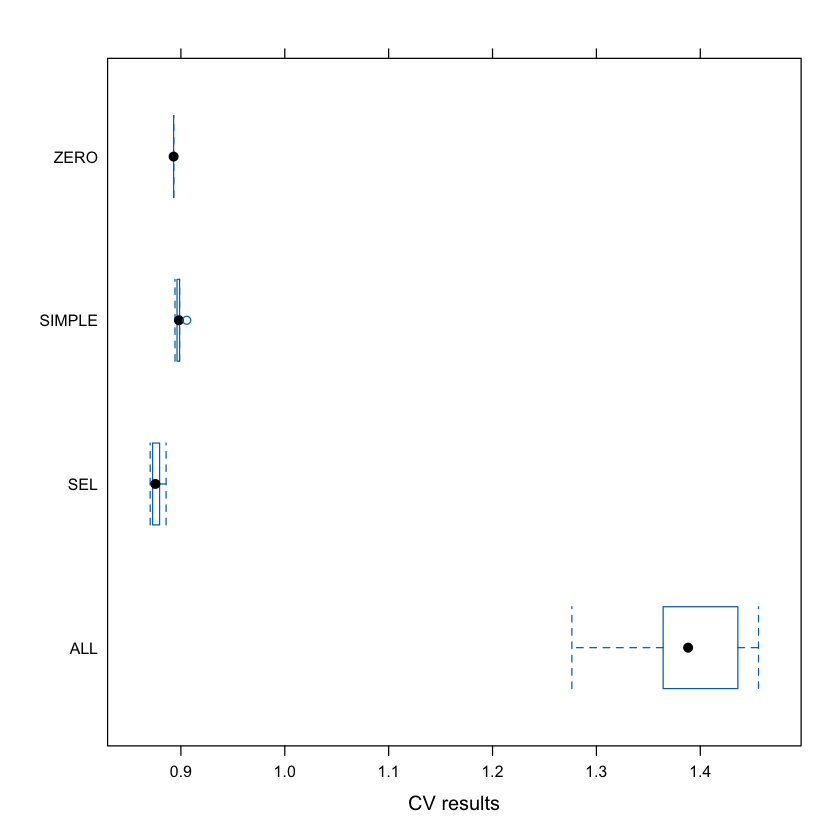

QUESTIONS

1. Show how the previously learned feature selection methods (p-values, stepwise selection, shrinkage) work in this case. Clearly demonstrate whether they work well/fail and explain why. Play with several different random generator seeds.
2. Describe step by step the correct way of model comparison procedure through cross-validation that was incorrectly implemented above. You can also implement the procedure, however, the implementation is optional only.


2. the issue with the crossvalidation above is data leakage. We are evaluating a model that is already fitted on the whole dataset (lm.all, lm.sel, etc.). To have a correct cross validation we need to fit models inside each of the cross validation fold.  The correct way of model comparison through crossvalidation is: 
- Define the model
- split data into K folds
- split data into training and testing sets
    -   fit the model only on the training set
    - make prediction on testing dataset
    - compute mean, std, confidence intervals
- compare models
